In [33]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import warnings


In [34]:
df = pd.read_csv("real_estate_prices.csv")

print("Rows and columns:", df.shape)

Rows and columns: (21613, 22)


In [35]:
df.head()

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  object 
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int64  
 11  condition      21613 non-null  int64  
 12  grade          21613 non-null  int64  
 13  sqft_above     21613 non-null  int64  
 14  sqft_basement  21613 non-null  int64  
 15  yr_built       21613 non-null  int64  
 16  yr_renovated   21613 non-null  int64  
 17  zipcode        21613 non-null  int64  
 18  lat   

In [37]:
df.columns = [
    re.sub(r'[^a-zA-Z0-9]+', '_', col.strip()).strip('_').lower()
    for col in df.columns
]

if "unnamed_0" in df.columns:
    df.drop(columns=["unnamed_0"], inplace=True)

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [38]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
id                0
date              0
price             0
bedrooms         13
bathrooms        10
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
grade             0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
zipcode           0
lat               0
long              0
sqft_living15     0
sqft_lot15        0
dtype: int64

Total missing values: 23


In [25]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Total missing values: 6201


In [39]:
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].median())

print("Missing values after handling:")
print(df.isnull().sum().sum())

Missing values after handling:
0


In [40]:
print("Duplicate rows before removal:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicate rows after removal:", df.duplicated().sum())

Duplicate rows before removal: 0
Duplicate rows after removal: 0


Data merging 

In [41]:
neighborhood_data = pd.DataFrame({
    "zipcode": [98001, 98002, 98003],
    "avg_income": [65000, 58000, 72000]
})

merged_df = df.merge(
    neighborhood_data,
    on="zipcode",
    how="left"
)

print("Merged dataset:")
display(merged_df.head())

print("Merged dataset shape:", merged_df.shape)

Merged dataset:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,avg_income
0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,1180,0,1955,0,98178,47.5112,-122.257,1340,5650,NaN
1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639,NaN
2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,0,...,770,0,1933,0,98028,47.7379,-122.233,2720,8062,NaN
3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,1050,910,1965,0,98136,47.5208,-122.393,1360,5000,NaN
4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,0,...,1680,0,1987,0,98074,47.6168,-122.045,1800,7503,NaN


Merged dataset shape: (21613, 22)


Filter and subset data : Filter properties sold in 2014

In [42]:
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y%m%dT%H%M%S",
    errors="coerce"
)

df_2014 = df[df["date"].dt.year == 2014].copy()

print("Properties sold in 2014:", len(df_2014))
display(df_2014.head())

Properties sold in 2014: 14633


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
5,7237550310,2014-05-12,1225000.0,4.0,4.50,5420,101930,1.0,0,0,...,11,3890,1530,2001,0,98053,47.6561,-122.005,4760,101930
6,1321400060,2014-06-27,257500.0,3.0,2.25,1715,6819,2.0,0,0,...,7,1715,0,1995,0,98003,47.3097,-122.327,2238,6819


Filter by property price

In [43]:
affordable_properties = df[df["price"] < 500000].copy()

print("Properties priced below $500,000:",
      len(affordable_properties))

display(affordable_properties.head())

Properties priced below $500,000: 12408


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
2,5631500400,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
6,1321400060,2014-06-27,257500.0,3.0,2.25,1715,6819,2.0,0,0,...,7,1715,0,1995,0,98003,47.3097,-122.327,2238,6819
7,2008000270,2015-01-15,291850.0,3.0,1.50,1060,9711,1.0,0,0,...,7,1060,0,1963,0,98198,47.4095,-122.315,1650,9711
8,2414600126,2015-04-15,229500.0,3.0,1.00,1780,7470,1.0,0,0,...,7,1050,730,1960,0,98146,47.5123,-122.337,1780,8113


Filter properties by location

In [32]:
location_name = "Electronic City Phase II"

location_properties = df[
    df["location"] == location_name
]

print(location_properties.head())
print("Number of properties:", len(location_properties))

                area_type   availability                  location   size  \
0    Super built-up  Area         19-Dec  Electronic City Phase II  2 BHK   
155  Super built-up  Area         18-Jul  Electronic City Phase II  2 BHK   
292  Super built-up  Area  Ready To Move  Electronic City Phase II  2 BHK   
354  Super built-up  Area         18-May  Electronic City Phase II  1 BHK   
461  Super built-up  Area         18-May  Electronic City Phase II  3 BHK   

     society total_sqft  bath  balcony  price  bedrooms  
0     Coomee       1056   2.0      1.0  39.07       2.0  
155  Sryalan       1020   2.0      1.0  30.60       2.0  
292  Coush W       1069   2.0      2.0  45.00       2.0  
354  SNbay G        630   1.0      1.0  28.35       1.0  
461  Sryalan       1220   2.0      1.0  35.23       3.0  
Number of properties: 128


Encode categorical variables

In [44]:
df_encoded = pd.get_dummies(
    df,
    columns=["waterfront"],
    dtype=int
)

print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)

display(df_encoded.head())

Original dataset shape: (21613, 21)
Encoded dataset shape: (21613, 22)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,waterfront_0,waterfront_1
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,3,...,0,1955,0,98178,47.5112,-122.257,1340,5650,1,0
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,3,...,400,1951,1991,98125,47.7210,-122.319,1690,7639,1,0
2,5631500400,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,3,...,0,1933,0,98028,47.7379,-122.233,2720,8062,1,0
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,5,...,910,1965,0,98136,47.5208,-122.393,1360,5000,1,0
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,3,...,0,1987,0,98074,47.6168,-122.045,1800,7503,1,0


Aggregate data and calculate summary statistics

In [45]:
price_by_zipcode = df.groupby("zipcode")["price"].agg(
    ["count", "mean", "min", "max"]
).round(2)

price_by_zipcode = price_by_zipcode.sort_values(
    by="mean",
    ascending=False
)

display(price_by_zipcode.head(10))

,count,mean,min,max
zipcode,,,,
98039,50,2160606.60,787500.0,6885000.0
98004,317,1355927.08,425000.0,7062500.0
98040,282,1194230.02,500000.0,5300000.0
98112,269,1095499.34,169317.0,3400000.0
98102,105,901258.27,330000.0,7700000.0
98109,109,879623.62,216650.0,3200000.0
98105,229,862825.23,380000.0,3650000.0
98006,498,859684.78,247500.0,4208000.0
98119,184,849448.02,300523.0,3065000.0


In [46]:
price_by_bedrooms = df.groupby("bedrooms")["price"].agg(
    ["count", "mean"]
).round(2)

display(price_by_bedrooms)

,count,mean
bedrooms,,
1.0,199,317642.88
2.0,2760,401372.68
3.0,9837,466157.11
4.0,6882,635419.50
5.0,1601,786599.83
6.0,272,825520.64
7.0,38,951184.66
8.0,13,1105076.92
9.0,6,893999.83


Identify and handle outliers

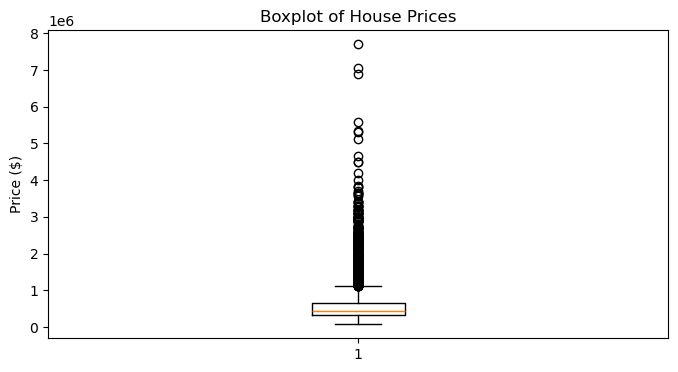

In [47]:
plt.figure(figsize=(8, 4))
plt.boxplot(df["price"])
plt.title("Boxplot of House Prices")
plt.ylabel("Price ($)")
plt.show()

In [48]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 321950.0
Q3: 645000.0
IQR: 323050.0
Lower limit: -162625.0
Upper limit: 1129575.0


In [49]:
outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
]

print("Number of price outliers:", len(outliers))

display(outliers[["price", "bedrooms", "bathrooms",
                  "sqft_living", "zipcode"]].head(10))

Number of price outliers: 1146


,price,bedrooms,bathrooms,sqft_living,zipcode
5,1225000.0,4.0,4.50,5420,98053
21,2000000.0,3.0,2.75,3050,98040
49,1350000.0,3.0,2.50,2753,98070
69,1325000.0,5.0,2.25,3200,98004
125,1450000.0,4.0,2.75,2750,98004
153,2250000.0,4.0,3.25,5180,98006
216,1505000.0,5.0,3.00,3300,98040
246,2400000.0,4.0,2.50,3650,98074
269,2900000.0,4.0,3.25,5050,98004
270,1365000.0,4.0,4.75,5310,98077


In [50]:
df_cleaned = df[
    (df["price"] >= lower_limit) &
    (df["price"] <= upper_limit)
].copy()

print("Original dataset shape:", df.shape)
print("Dataset shape after outlier removal:", df_cleaned.shape)

Original dataset shape: (21613, 21)
Dataset shape after outlier removal: (20467, 21)


In [51]:
print("Final dataset shape:", df_cleaned.shape)

print("\nMissing values:")
print(df_cleaned.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_cleaned.duplicated().sum())

print("\nFinal dataset:")
display(df_cleaned.head())

print("\nStatistical summary:")
display(df_cleaned.describe())

Final dataset shape: (20467, 21)

Missing values:
0

Duplicate rows:
0

Final dataset:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503



Statistical summary:


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.046700e+04,20467,2.046700e+04,20467.000000,20467.000000,20467.000000,2.046700e+04,20467.000000,20467.000000,20467.000000,...,20467.000000,20467.000000,20467.000000,20467.000000,20467.000000,20467.000000,20467.000000,20467.000000,20467.000000,20467.000000
mean,4.603223e+09,2014-10-29 04:55:51.111545344,4.769846e+05,3.331509,2.052621,1975.558167,1.461041e+04,1.476035,0.002980,0.172668,...,7.530561,1708.330972,267.227195,1970.811013,74.681145,98078.555773,47.556888,-122.213265,1922.255191,12447.084526
min,1.000102e+06,2014-05-02 00:00:00,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.131701e+09,2014-07-22 00:00:00,3.150000e+05,3.000000,1.500000,1400.000000,5.000000e+03,1.000000,0.000000,0.000000,...,7.000000,1170.000000,0.000000,1951.000000,0.000000,98033.000000,47.460400,-122.330000,1470.000000,5046.000000
50%,3.905082e+09,2014-10-16 00:00:00,4.375000e+05,3.000000,2.000000,1860.000000,7.500000e+03,1.000000,0.000000,0.000000,...,7.000000,1520.000000,0.000000,1974.000000,0.000000,98065.000000,47.567000,-122.232000,1800.000000,7542.000000
75%,7.338101e+09,2015-02-17 00:00:00,6.000000e+05,4.000000,2.500000,2431.000000,1.031900e+04,2.000000,0.000000,0.000000,...,8.000000,2100.000000,510.000000,1996.000000,0.000000,98118.000000,47.679800,-122.123000,2280.000000,9883.500000
max,9.900000e+09,2015-05-24 00:00:00,1.127500e+06,33.000000,7.500000,7480.000000,1.651359e+06,3.500000,1.000000,4.000000,...,12.000000,5710.000000,2720.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,5380.000000,871200.000000
std,2.877364e+09,NaN,2.083713e+05,0.909350,0.710616,774.833460,4.010956e+04,0.537033,0.054513,0.640950,...,1.039192,727.296461,409.031661,29.160540,378.761647,53.336953,0.141038,0.142412,614.932010,26538.592250


In [52]:
df_cleaned.to_csv(
    "cleaned_real_estate_prices.csv",
    index=False
)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully
